<a href="https://colab.research.google.com/github/Manojgowdabh/GOWDA/blob/main/Safe_door_management_NMG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📱💡 Week 4: Give It Hands
### IoT: a phone switches on a light in Wokwi

**The project:** your laptop camera looks for a phone. When it sees one, a light (or buzzer) turns on inside a **Wokwi** simulation. When the phone leaves, it turns off.

**How to use this notebook**
1. Run the cells **from top to bottom**, one at a time (press ▶ on the left of each cell).
2. Cells marked **🔌 WOKWI** are not Python. Copy that code into [wokwi.com](https://wokwi.com) instead.
3. Use **Chrome**, and click **Allow** when it asks for the camera.

```
Browser camera -> Colab (YOLO looks for a phone) --publish "led"/"off"--> [ MQTT broker ] --> Wokwi ESP32 --> LED / buzzer
```

## Step 0 · Install (start this first!)
It takes 1 to 2 minutes. Press play and carry on reading while it runs.

In [ ]:
!pip install -q ultralytics paho-mqtt

## Step 1 · Pick your unique topic
A **topic** is like a WhatsApp group name. If two people use the same topic, they switch **each other's** lights. So make yours unique: your first name + roll number, lowercase, no spaces.

In [ ]:
YOUR_NAME = "nmg3128"     # <- CHANGE THIS (example: Sathwik042)

BROKER = "broker.hivemq.com"  # backup brokers: broker.emqx.io, test.mosquitto.org

import re
assert (
    re.fullmatch(r"[a-z0-9]+", YOUR_NAME) and YOUR_NAME != "yourname123"
), "Change YOUR_NAME to your own first name + roll number (lowercase letters and numbers only)"

TOPIC = f"ssse/w4/{YOUR_NAME}/cmd"
print("Your topic is:")
print(TOPIC)
print("\nCopy this EXACT text into the TOPIC line of the Wokwi code.")

Your topic is:
ssse/w4/nmg3128/cmd

Copy this EXACT text into the TOPIC line of the Wokwi code.


## Step 2 · 🔌 WOKWI: build the circuit
Open [wokwi.com](https://wokwi.com) → **New Project → ESP32**. Add 2 LEDs, 2 resistors (220 Ω) and a buzzer.

| Part | Connection |
|---|---|
| Green LED | GPIO 26 → 220 Ω resistor → LED → GND |
| Red LED | GPIO 27 → 220 Ω resistor → LED → GND |
| Buzzer | pin 1 → GPIO 25, pin 2 → GND |

**Blink test first** (no WiFi). Paste this into the Wokwi code box and press ▶. The green LED should blink.

```cpp
void setup() { pinMode(26, OUTPUT); }
void loop() {
  digitalWrite(26, HIGH); delay(500);
  digitalWrite(26, LOW);  delay(500);
}
```

Not blinking? It's the wiring. Not the AI, not the WiFi.

## Step 3 · 🔌 WOKWI: teach the ESP32 to listen
1. In Wokwi, open the **Library Manager** (book icon) and add **PubSubClient**.
2. Replace the code with the sketch below.
3. Change the `TOPIC` line to the topic printed in Step 1.
4. Press ▶. The Serial Monitor should say `MQTT connected, listening on ...`.

```cpp

#include <WiFi.h>
#include <PubSubClient.h>

// =====================================
// WIFI CONFIGURATION
// =====================================

const char* WIFI_SSID = "Wokwi-GUEST";
const char* WIFI_PASS = "";

// =====================================
// MQTT CONFIGURATION
// =====================================

const char* BROKER = "broker.hivemq.com";
const int MQTT_PORT = 1883;

const char* TOPIC = "ssse/w4/nmg3128/cmd";

// =====================================
// GPIO CONFIGURATION
// =====================================

const int GREEN_LED = 26;
const int RED_LED = 27;
const int BUZZER = 25;

// =====================================
// NETWORK OBJECTS
// =====================================

WiFiClient espClient;
PubSubClient mqtt(espClient);

// =====================================
// TIMERS
// =====================================

unsigned long lastMqttAttempt = 0;

const unsigned long MQTT_RETRY_INTERVAL = 5000;

// =====================================
// LED CONTROL
// =====================================

void setLEDs(bool green, bool red) {

  digitalWrite(GREEN_LED, green ? HIGH : LOW);
  digitalWrite(RED_LED, red ? HIGH : LOW);

}

// =====================================
// BUZZER
// =====================================

void beep(int duration) {

  unsigned long start = millis();

  while (millis() - start < (unsigned long)duration) {

    digitalWrite(BUZZER, HIGH);
    delayMicroseconds(500);

    digitalWrite(BUZZER, LOW);
    delayMicroseconds(500);

  }

  digitalWrite(BUZZER, LOW);

}

// =====================================
// MQTT MESSAGE CALLBACK
// =====================================

void onMessage(char* topic, byte* payload, unsigned int len) {

  String msg = "";

  for (unsigned int i = 0; i < len; i++) {
    msg += (char)payload[i];
  }

  msg.trim();

  Serial.println("\n======================");
  Serial.print("COMMAND RECEIVED: ");
  Serial.println(msg);

  if (msg == "led") {

    // GREEN ON, RED OFF
    setLEDs(true, false);

    digitalWrite(BUZZER, LOW);

    Serial.println("GREEN LED: ON");
    Serial.println("RED LED: OFF");

  }

  else if (msg == "buzz") {

    // RED ON, GREEN OFF
    setLEDs(false, true);

    Serial.println("RED LED: ON");
    Serial.println("GREEN LED: OFF");
    Serial.println("BUZZER: ON");

    beep(400);

    Serial.println("BUZZER: OFF");
    Serial.println("RED LED REMAINS ON");

  }

  else if (msg == "off") {

    // EVERYTHING OFF
    setLEDs(false, false);

    digitalWrite(BUZZER, LOW);

    Serial.println("GREEN LED: OFF");
    Serial.println("RED LED: OFF");
    Serial.println("BUZZER: OFF");

  }

  else {

    Serial.println("UNKNOWN COMMAND");

  }

  Serial.println("======================");

}

// =====================================
// WIFI CONNECTION
// =====================================

void connectWiFi() {

  Serial.println("\nConnecting to WiFi...");

  WiFi.mode(WIFI_STA);
  WiFi.begin(WIFI_SSID, WIFI_PASS, 6);

  int attempts = 0;

  while (WiFi.status() != WL_CONNECTED && attempts < 50) {

    delay(300);
    Serial.print(".");

    attempts++;

  }

  if (WiFi.status() == WL_CONNECTED) {

    Serial.println("\nWiFi Connected!");

    Serial.print("IP Address: ");
    Serial.println(WiFi.localIP());

  }

  else {

    Serial.println("\nWiFi Connection Failed!");

    Serial.print("Status: ");
    Serial.println(WiFi.status());

  }

}

// =====================================
// MQTT CONNECTION
// =====================================

void connectMqtt() {

  if (mqtt.connected()) return;

  Serial.println("\nConnecting to HiveMQ...");

  // Generate a unique client ID
  String clientID = "ESP32-";
  clientID += String((uint32_t)esp_random(), HEX);

  if (mqtt.connect(clientID.c_str())) {

    Serial.println("MQTT CONNECTED!");

    if (mqtt.subscribe(TOPIC)) {

      Serial.println("SUBSCRIPTION SUCCESSFUL!");

      Serial.print("Topic: ");
      Serial.println(TOPIC);

    }

    else {

      Serial.println("Subscription Failed!");

    }

  }

  else {

    Serial.print("MQTT CONNECTION FAILED!");
    Serial.print(" Error Code: ");
    Serial.println(mqtt.state());

  }

}

// =====================================
// SETUP
// =====================================

void setup() {

  Serial.begin(115200);

  Serial.println("\nESP32 MQTT CONTROL SYSTEM");
  Serial.println("=========================");

  pinMode(GREEN_LED, OUTPUT);
  pinMode(RED_LED, OUTPUT);
  pinMode(BUZZER, OUTPUT);

  setLEDs(false, false);
  digitalWrite(BUZZER, LOW);

  // Connect WiFi
  connectWiFi();

  // Configure MQTT
  mqtt.setServer(BROKER, MQTT_PORT);
  mqtt.setCallback(onMessage);

  mqtt.setKeepAlive(30);
  mqtt.setSocketTimeout(10);

  Serial.println("\nSYSTEM READY!");

}

// =====================================
// MAIN LOOP
// =====================================

void loop() {

  // Check WiFi
  if (WiFi.status() != WL_CONNECTED) {

    if (millis() - lastMqttAttempt >= MQTT_RETRY_INTERVAL) {

      lastMqttAttempt = millis();

      Serial.println("WiFi disconnected. Reconnecting...");

      WiFi.disconnect();
      WiFi.begin(WIFI_SSID, WIFI_PASS, 6);

    }

    return;

  }

  // Check MQTT
  if (!mqtt.connected()) {

    if (millis() - lastMqttAttempt >= MQTT_RETRY_INTERVAL) {

      lastMqttAttempt = millis();

      connectMqtt();

    }

  }

  else {

    mqtt.loop();

  }

}

```

**What the messages do:** `led` → green LED on · `buzz` → red LED + beep · `off` → everything off.

## Step 4 · Test the Wokwi half on its own (no AI yet)
You are the remote control. Keep Wokwi running (▶) and watch it while you run this cell.

> Always test one half at a time. If nothing happens, the problem is on the Wokwi side or in the topic name. Not the AI.

In [ ]:
import time
import paho.mqtt.publish as publish

def send(msg):
    publish.single(TOPIC, msg, hostname=BROKER, port=1883)
    print("sent:", msg)

send("led")    # green LED should light in Wokwi
time.sleep(2)
send("buzz")   # red LED + beep
time.sleep(2)
send("off")

ERROR:paho.mqtt.client:Client is not connected. Socket: None). Last known Connection State: MQTT_CS_DISCONNECTED


sent: led


ERROR:paho.mqtt.client:Client is not connected. Socket: None). Last known Connection State: MQTT_CS_DISCONNECTED


sent: buzz


ERROR:paho.mqtt.client:Client is not connected. Socket: None). Last known Connection State: MQTT_CS_DISCONNECTED


sent: off


## Step 5 · Camera helpers
The camera runs in your **browser**. These three functions grab one picture at a time (roughly 2 to 4 per second, so it's "live enough" for a light switch, not smooth video).

Just run this cell. You don't need to understand the JavaScript.

In [ ]:
import time, cv2, numpy as np
from base64 import b64decode
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js

def start_camera():
    display(Javascript('''
      async function startCam() {
        const video = document.createElement('video');
        video.style.width = '240px';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(video);
        video.srcObject = stream;
        await video.play();
        window.cam = {video: video, stream: stream, canvas: document.createElement('canvas')};
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      }
    '''))
    eval_js('startCam()')

def get_frame(quality=0.6):
    data = eval_js('''
      (function() {
        const c = window.cam;
        c.canvas.width = c.video.videoWidth;
        c.canvas.height = c.video.videoHeight;
        c.canvas.getContext('2d').drawImage(c.video, 0, 0);
        return c.canvas.toDataURL('image/jpeg', %s);
      })()
    ''' % quality)
    jpg = b64decode(data.split(',')[1])
    return cv2.imdecode(np.frombuffer(jpg, np.uint8), cv2.IMREAD_COLOR)

def stop_camera():
    eval_js('window.cam.stream.getTracks().forEach(t => t.stop())')

print("Camera helpers ready")

Camera helpers ready


## Step 6 · What does YOLO see? (one frame)
**YOLO** is an AI that was already trained on millions of images. It knows 80 everyday objects, including `cell phone` and `person`. No training needed.

Hold your phone up to the camera, then run this cell.

> ⚠️ `start_camera()` and `get_frame()` must run **in the same cell**. Colab keeps each cell's camera separate.

<IPython.core.display.Javascript object>

I can see: ['person']


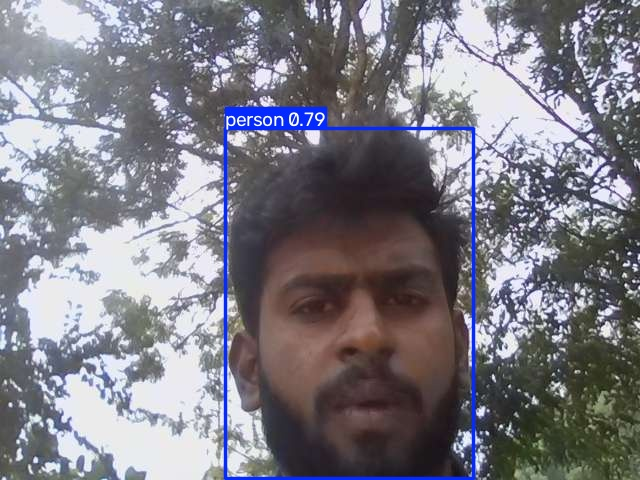

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")        # downloads ~6 MB the first time (if it fails, use "yolo11n.pt")

start_camera()
time.sleep(1)                     # the very first frame is often black
frame = get_frame()
result = model(frame, verbose=False, conf=0.4)[0]
print("I can see:", [result.names[int(c)] for c in result.boxes.cls])
display(Image(data=cv2.imencode(".jpg", result.plot())[1].tobytes()))
stop_camera()

## Step 7 · 🎯 The phone controls the light
Put this tab and the Wokwi tab **side by side**, make sure Wokwi is running (▶), then run the cell. Show your phone: the green LED lights up. Hide it: the light goes off about a second later.

Two rules keep it from flickering:
- **ON** only after the phone is seen in **2 frames in a row**. **OFF** only after **3 frames in a row** without it.
- It sends a message **only when something changes**.

> A model is never 100% sure. That is why we wait for 2 frames. Real systems do the same.

Tips: hold the phone fairly close, screen or back facing the camera, in good light. Press ■ on the cell to stop early.

MQTT Broker: broker.hivemq.com
MQTT Topic: ssse/w4/manoj1234/cmd
YOLO model loaded successfully!


<IPython.core.display.Javascript object>

Person detected!


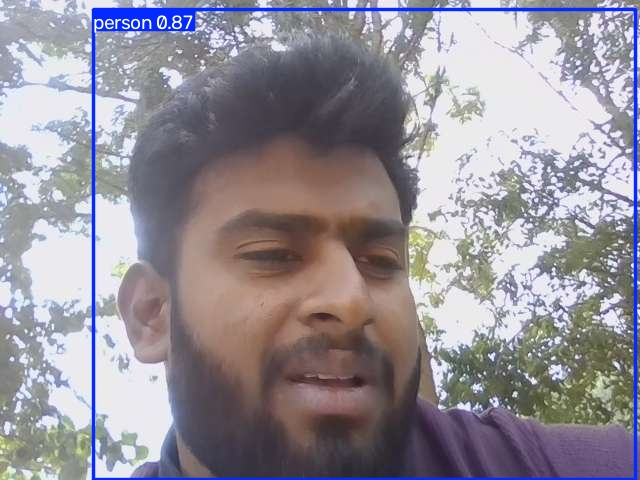

Person detected!


ERROR:paho.mqtt.client:Client is not connected. Socket: None). Last known Connection State: MQTT_CS_DISCONNECTED


MQTT message sent: open
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
No person detected!
Person detected!
Person detected!
No person detected!
No person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected!
Person detected

ERROR:paho.mqtt.client:Client is not connected. Socket: None). Last known Connection State: MQTT_CS_DISCONNECTED


MQTT message sent: close
Smart Door system stopped.


In [ ]:

# ==========================================
# SMART DOOR - GOOGLE COLAB CODE
# YOLO PERSON DETECTION + MQTT
# ==========================================

!pip install -q ultralytics paho-mqtt

import cv2
import time
from ultralytics import YOLO
import paho.mqtt.publish as publish
from IPython.display import display, Image

# ==========================================
# STEP 1: MQTT CONFIGURATION
# ==========================================

YOUR_NAME = "manoj1234"  # CHANGE THIS to your name + roll number

BROKER = "broker.hivemq.com"
TOPIC = f"ssse/w4/{YOUR_NAME}/cmd"

print("MQTT Broker:", BROKER)
print("MQTT Topic:", TOPIC)

# ==========================================
# STEP 2: LOAD YOLO MODEL
# ==========================================

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

# ==========================================
# STEP 3: MQTT MESSAGE FUNCTION
# ==========================================

def send(msg):
    publish.single(
        TOPIC,
        msg,
        hostname=BROKER,
        port=1883
    )
    print("MQTT message sent:", msg)

# ==========================================
# STEP 4: MANUAL TEST
# ==========================================

# Uncomment one line at a time to test:
# send("open")   # Open the door
# send("close")  # Close the door

# ==========================================
# STEP 5: CAMERA
# ==========================================

# Keep your teacher's existing camera helper cells:
# start_camera()
# get_frame()
# stop_camera()

# ==========================================
# STEP 6: PERSON DETECTION SETTINGS
# ==========================================

TARGET = "person"

ON_MSG = "open"
OFF_MSG = "close"

ON_AFTER = 2       # Open after 2 consecutive detections
OFF_AFTER = 3      # Close after 3 consecutive misses

RUN_SECONDS = 120  # Run for 2 minutes

# ==========================================
# STEP 7: SMART DOOR AUTOMATION
# ==========================================

start_camera()
time.sleep(1)

hits = 0
misses = 0
last_sent = None
view = None

t0 = time.time()

try:
    while time.time() - t0 < RUN_SECONDS:

        frame = get_frame()

        # YOLO detects objects in the camera frame
        result = model(frame, verbose=False, conf=0.4)[0]

        # Check whether a person is detected
        detected_classes = [
            result.names[int(c)]
            for c in result.boxes.cls
        ]

        person_detected = TARGET in detected_classes

        if person_detected:
            hits += 1
            misses = 0
            print("Person detected!")

        else:
            misses += 1
            hits = 0
            print("No person detected!")

        # Decide whether to open or close the door
        msg = None

        if hits >= ON_AFTER:
            msg = ON_MSG

        elif misses >= OFF_AFTER:
            msg = OFF_MSG

        # Send MQTT only when the door state changes
        if msg is not None and msg != last_sent:
            send(msg)
            last_sent = msg

        # Display camera with YOLO detection boxes
        img_bytes = cv2.imencode(
            ".jpg",
            result.plot()
        )[1].tobytes()

        img = Image(data=img_bytes)

        if view is None:
            view = display(img, display_id=True)
        else:
            view.update(img)

except KeyboardInterrupt:
    print("Detection stopped by user.")

finally:
    stop_camera()

    # Close the door when the program stops
    send("close")

    print("Smart Door system stopped.")


## Step 8 · Tinker (change ONE thing at a time)
Edit the settings at the top of the Step 7 cell and run it again.

| Try this | Change |
|---|---|
| Buzzer instead of light | `ON_MSG = "buzz"` |
| A person instead of a phone | `TARGET = "person"` (everyone is in front of the camera, so it stays on. Walk out of view to turn it off) |
| Other objects | `TARGET = "bottle"` / `"cup"` / `"book"` / `"laptop"` |
| More or less patient | change `ON_AFTER` and `OFF_AFTER` |

**Fast finishers:** swap YOLO for your own Week 2 finger-counting model and map fingers to `led` / `buzz` / `off`.

## 🛠 When it breaks
| Problem | Likely cause / fix |
|---|---|
| Wokwi stuck on `....` | Make sure the code has `WiFi.begin("Wokwi-GUEST", "", 6)` (the sketch above does) |
| Wokwi "compiling" takes forever | Many people compiling at once. Wait a minute, then try again |
| Serial says MQTT failed, rc=-2 | Broker unreachable. Change `BROKER` to `broker.emqx.io` in **both** Wokwi and Step 1 here |
| Message sent, nothing happens | Topic differs by one character between Wokwi and Colab. Print `TOPIC` and compare |
| Light flickers on and off | Two people share a topic, or two clients share an ID |
| `ModuleNotFoundError` | Run the Step 0 install cell first |
| Camera cell does nothing | Browser blocked the camera. Click the 🔒 icon, allow camera, rerun |
| `window.cam` is undefined | `start_camera()` and `get_frame()` are in different cells. Put them in the same cell |
| First frame is black | Add `time.sleep(1)` after `start_camera()` (already in the code) |
| Phone never detected | Too far, too dark or screen glare. Move closer, add light, or lower `conf=0.4` to `0.3` |
| Light turns on with no phone | Another object looks like one. Raise `conf` to `0.5`, or raise `ON_AFTER` |
| Image doesn't update in place | Delete the `view` lines and just watch the Wokwi light |
| Very slow | Lower the camera quality: `get_frame(quality=0.4)` |
| Can't download YOLO weights | Use `yolo11n.pt` instead of `yolov8n.pt` |

## 🏠 Homework
Pick your detect → action pair from the **Week 4 challenge sheet** and build it, using either YOLO's objects or your own Week 2/3 model. Wokwi has LEDs, buzzers, servos and relays. Where a challenge mentions a motor or conveyor, use an LED or servo as the stand-in. Bring it working to Week 5.

> ⚠️ A public broker is open to anyone who guesses your topic. Fine for a demo. Never for anything real.